# EDA of the results table (Ivy)

Exploratory analysis of `processed/results_clean.csv`: one row per driver per race.

**Questions this answers (from the proposal's EDA objective)**
1. How strongly does grid position predict finishing position, and how does that change with grid slot and year?
2. How often do pole-sitters win, and how many places are gained or lost from each slot?
3. How often do drivers retire, when in the race, and which teams and circuits are worst?
4. How do teams compare on finishing position and points?
5. How close are the races (gaps to the winner), and how do pit-lane starters fare?

**Seasons and the split.** This notebook describes all five seasons (2021 to 2025) for the report. Each season is labelled `train` (2021 to 2023), `validation` (2024) or `test` (2025). The split itself is applied later, in the combined modelling work. One rule: anything you *learn here* and then use to make a modelling choice (which features to keep, what thresholds to set) must come from the **training-only numbers at the end of this notebook**, not from 2024 or 2025.

Figures are saved to `figures/` for the report.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

RESULTS_FILE = Path("processed") / "results_clean.csv"
EDA_YEARS = [2021, 2022, 2023, 2024, 2025]
SPLIT = {2021: "train", 2022: "train", 2023: "train", 2024: "validation", 2025: "test"}
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"results_{name}.png", dpi=150)

## 2. Load and select the races to explore

In [2]:
res = pd.read_csv('results_clean.csv', low_memory=False)
print("Whole file:", res.shape, "| years in file:", sorted(res["year"].unique()))

races = res[(res["session"] == "Race") & (res["year"].isin(EDA_YEARS))].copy()
races["split"] = races["year"].map(SPLIT)
started = races[~races["did_not_start"]].copy()                 # drivers who actually started
print("Explored:", len(races), "rows,", races.groupby(["year", "round"]).ngroups, "races, years", EDA_YEARS)

# For grid-vs-finish questions: need both positions, and skip the half-points Belgium 2021 race
gridded = started[started["grid_position"].notna() & started["finish_position"].notna()
                  & ~started["reduced_points_race"]].copy()
print("Rows used for grid-vs-finish analysis:", len(gridded))

Whole file: (2278, 40) | years in file: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Explored: 2278 rows, 114 races, years [2021, 2022, 2023, 2024, 2025]
Rows used for grid-vs-finish analysis: 2243


## 3. Overview per season

In [3]:
overview = races.groupby("year").agg(
    races=("round", "nunique"),
    driver_rows=("driver", "size"),
    drivers=("driver", "nunique"),
    retirements=("retired", "sum"),
    dns=("did_not_start", "sum"),
    disqualified=("disqualified", "sum"),
    pit_lane_starts=("pit_lane_start", "sum"),
)
overview.insert(0, "split", [SPLIT[y] for y in overview.index])
overview

,split,races,driver_rows,drivers,retirements,dns,disqualified,pit_lane_starts
year,,,,,,,,
2021,train,22,440,21,55,3,1,12
2022,train,22,440,22,73,1,0,10
2023,train,22,440,22,59,5,2,2
2024,validation,24,479,24,49,3,2,1
2025,test,24,479,21,51,3,6,0


## 4. Grid position vs finishing position
Spearman rank correlation is used because positions are ranks. 1.0 would mean everyone finishes where they started.

In [4]:
rho_all = gridded["grid_position"].corr(gridded["finish_position"], method="spearman")
print(f"Spearman correlation, grid vs finish ({EDA_YEARS}): {rho_all:.3f}")

per_year = {y: g["grid_position"].corr(g["finish_position"], method="spearman")
            for y, g in gridded.groupby("year")}
print("By year:", {y: round(v, 3) for y, v in per_year.items()})

Spearman correlation, grid vs finish ([2021, 2022, 2023, 2024, 2025]): 0.630
By year: {2021: np.float64(0.635), 2022: np.float64(0.523), 2023: np.float64(0.596), 2024: np.float64(0.736), 2025: np.float64(0.65)}


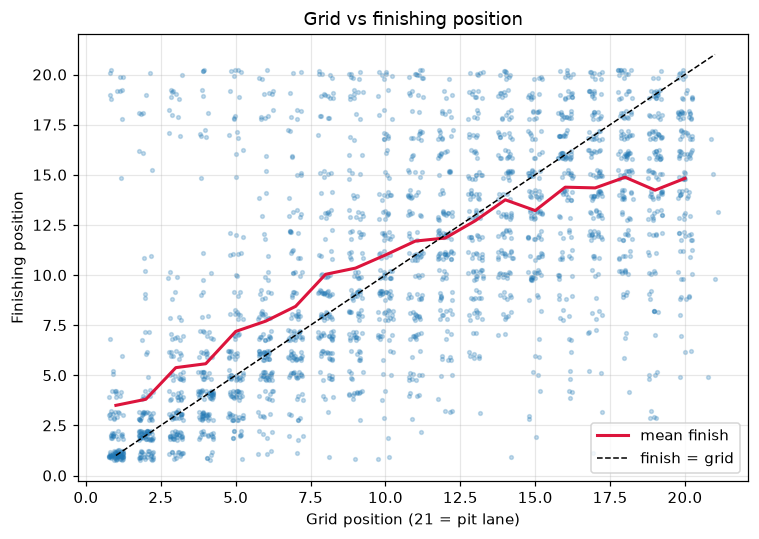

In [5]:
slot = gridded.groupby("grid_position")["finish_position"].agg(["mean", "std", "count"])
slot = slot[slot["count"] >= 10]

rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(gridded["grid_position"] + rng.uniform(-.25, .25, len(gridded)),
           gridded["finish_position"] + rng.uniform(-.25, .25, len(gridded)), s=6, alpha=.25)
ax.plot(slot.index, slot["mean"], color="crimson", lw=2, label="mean finish")
ax.plot([1, 21], [1, 21], "k--", lw=1, label="finish = grid")
ax.set_xlabel("Grid position (21 = pit lane)")
ax.set_ylabel("Finishing position")
ax.set_title("Grid vs finishing position")
ax.legend()
save(fig, "grid_vs_finish")

A car on pole can only lose places and a car at the back can only gain them, so the bars slope from green to red by construction. What matters is how steep the slope is and where it crosses zero.

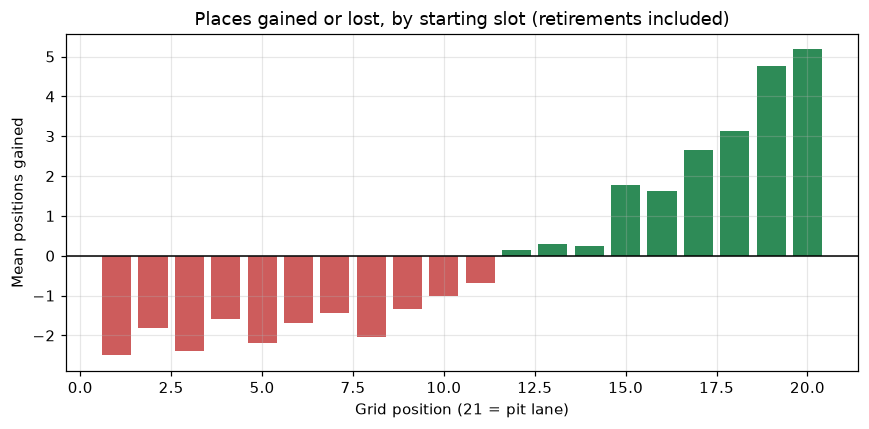

In [6]:
gain = gridded.groupby("grid_position")["positions_gained"].agg(["mean", "count"])
gain = gain[gain["count"] >= 10]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(gain.index, gain["mean"], color=np.where(gain["mean"] >= 0, "seagreen", "indianred"))
ax.axhline(0, color="k", lw=1)
ax.set_xlabel("Grid position (21 = pit lane)")
ax.set_ylabel("Mean positions gained")
ax.set_title("Places gained or lost, by starting slot (retirements included)")
save(fig, "positions_gained_by_slot")

## 5. How often does each grid slot win, podium or score?

,win,podium,scored_points
grid_position,,,
1,0.545,0.795,0.902
2,0.214,0.759,0.911
3,0.106,0.487,0.894
4,0.044,0.354,0.894
5,0.009,0.212,0.796
6,0.027,0.106,0.823
7,0.009,0.080,0.732
8,0.009,0.018,0.670
9,0.009,0.018,0.593


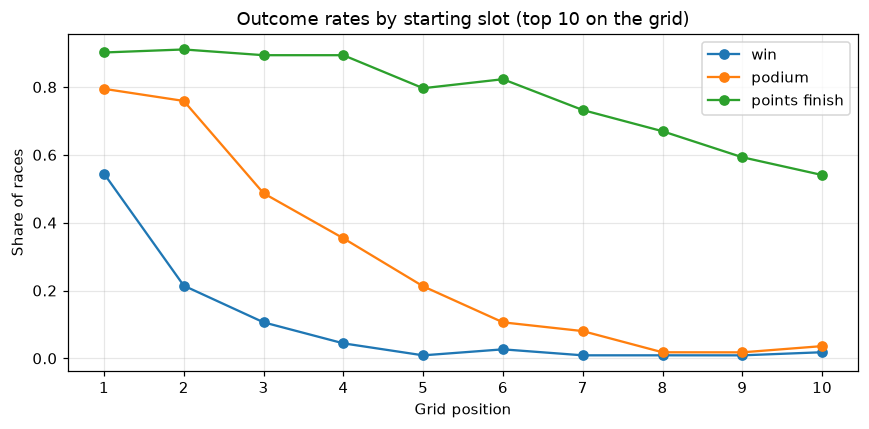

In [7]:
top = gridded[gridded["grid_position"] <= 10]
rates = top.groupby("grid_position")[["win", "podium", "scored_points"]].mean()
rates.index = rates.index.astype(int)

fig, ax = plt.subplots(figsize=(8, 4))
for col, lab in [("win", "win"), ("podium", "podium"), ("scored_points", "points finish")]:
    ax.plot(rates.index, rates[col], marker="o", label=lab)
ax.set_xlabel("Grid position")
ax.set_ylabel("Share of races")
ax.set_xticks(range(1, 11))
ax.set_title("Outcome rates by starting slot (top 10 on the grid)")
ax.legend()
save(fig, "outcome_by_slot")
rates.round(3)

In [8]:
pole = gridded[gridded["grid_position"] == 1]
pole_table = pole.groupby("year").agg(poles=("win", "size"), converted_to_win=("win", "mean"), podium=("podium", "mean"))
pole_table.loc["all"] = [len(pole), pole["win"].mean(), pole["podium"].mean()]
pole_table["poles"] = pole_table["poles"].astype(int)
pole_table.round(3)

,poles,converted_to_win,podium
year,,,
2021,20,0.500,0.750
2022,22,0.455,0.727
2023,22,0.636,0.909
2024,24,0.458,0.750
2025,24,0.667,0.833
all,112,0.545,0.795


## 6. Retirements
`retired` means did not finish and was not disqualified. The denominator below is drivers who started.

In [9]:
print("Retirement rate per season (share of starters):")
print(started.groupby("year")["retired"].mean().round(3).to_string())

by_team = started.groupby("team_group")["retired"].agg(["mean", "sum", "count"]).sort_values("mean", ascending=False)
by_team.columns = ["retirement_rate", "retirements", "starts"]
by_team.round(3)

Retirement rate per season (share of starters):
year
2021    0.126
2022    0.166
2023    0.136
2024    0.103
2025    0.107


,retirement_rate,retirements,starts
team_group,,,
Williams,0.227,51,225
RB,0.150,34,226
Alpine,0.142,32,226
Sauber,0.137,31,227
Haas,0.133,30,226
Aston Martin,0.129,29,224
Ferrari,0.102,23,225
Red Bull,0.096,22,228
Mercedes,0.092,21,228


In [10]:
by_event = (started.groupby("event")["retired"].agg(["mean", "sum", "count"])
            .rename(columns={"mean": "retirement_rate", "sum": "retirements", "count": "starts"}))
by_event = by_event[by_event["starts"] >= 30].sort_values("retirement_rate", ascending=False)
print("Highest-retirement circuits (events with at least 30 starts):")
by_event.head(10).round(3)

Highest-retirement circuits (events with at least 30 starts):


,retirement_rate,retirements,starts
event,,,
Australian Grand Prix,0.253,20,79
Saudi Arabian Grand Prix,0.172,17,99
Qatar Grand Prix,0.165,13,79
British Grand Prix,0.163,16,98
Canadian Grand Prix,0.162,13,80
Azerbaijan Grand Prix,0.160,16,100
São Paulo Grand Prix,0.155,15,97
Singapore Grand Prix,0.152,12,79
Mexico City Grand Prix,0.152,15,99


Retirements within the first lap (1 lap completed or fewer): 20.2%
Retired in the final 10% of the race: 12.5%


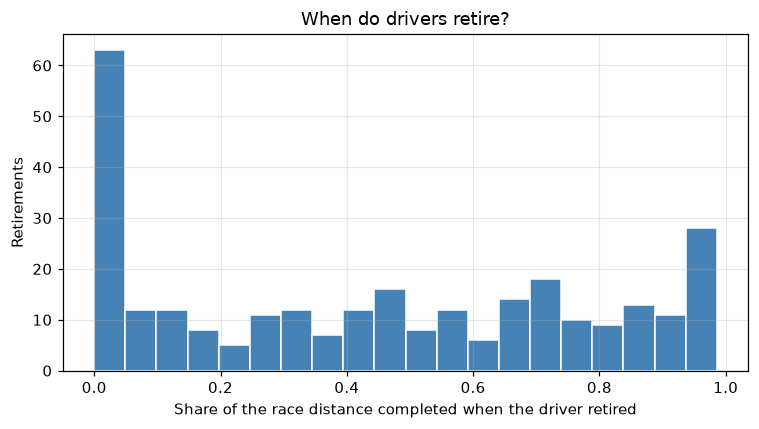

In [11]:
ret = started[started["retired"]]

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(ret["laps_completed_share"].dropna(), bins=20, color="steelblue", edgecolor="white")
ax.set_xlabel("Share of the race distance completed when the driver retired")
ax.set_ylabel("Retirements")
ax.set_title("When do drivers retire?")
save(fig, "retirement_timing")

print(f"Retirements within the first lap (1 lap completed or fewer): {(ret['laps_completed'] <= 1).mean():.1%}")
print(f"Retired in the final 10% of the race: {(ret['laps_completed_share'] >= 0.9).mean():.1%}")

In [12]:
# Cause split. From 2023 the source mostly says just 'Retired', so only trust 2021-2022.
cause = ret.groupby(["year", "status_group"]).size().unstack(fill_value=0)
cause

status_group,Accident/Collision,Mechanical,Retired (unspecified)
year,,,
2021,30,22,3
2022,32,41,0
2023,5,1,53
2024,0,0,49
2025,0,0,51


## 7. Teams and drivers

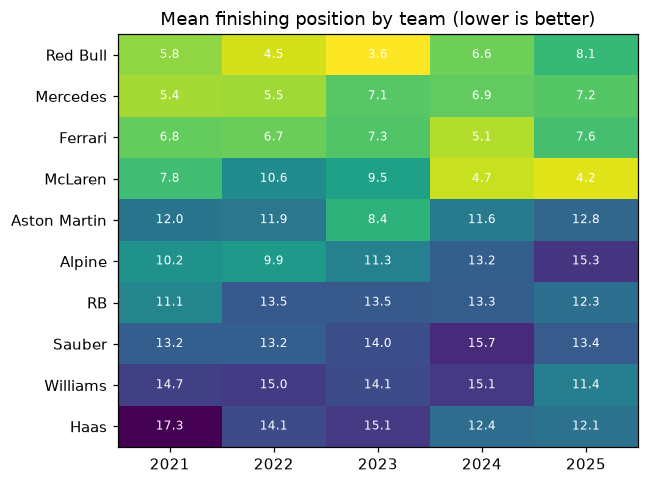

In [13]:
pv = started.pivot_table(index="team_group", columns="year", values="finish_position", aggfunc="mean")
pv = pv.loc[pv.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(pv.values, cmap="viridis_r", aspect="auto")
ax.grid(False)
ax.set_xticks(range(len(pv.columns)))
ax.set_xticklabels(pv.columns)
ax.set_yticks(range(len(pv.index)))
ax.set_yticklabels(pv.index)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        if not np.isnan(pv.values[i, j]):
            ax.text(j, i, f"{pv.values[i, j]:.1f}", ha="center", va="center", color="white", fontsize=8)
ax.set_title("Mean finishing position by team (lower is better)")
save(fig, "team_mean_finish")

In [14]:
team_pts = started.groupby(["year", "team_group"])["points"].sum().unstack(0).fillna(0)
team_pts = team_pts.loc[team_pts.sum(axis=1).sort_values(ascending=False).index]
team_pts

year,2021,2022,2023,2024,2025
team_group,,,,,
Red Bull,578.5,724.0,790.0,537.0,410.0
Mercedes,604.5,495.0,374.0,433.0,424.0
Ferrari,322.5,519.0,363.0,595.0,360.0
McLaren,274.0,150.0,266.0,609.0,775.0
Aston Martin,77.0,55.0,266.0,94.0,80.0
Alpine,155.0,170.0,110.0,63.0,20.0
RB,142.0,35.0,22.0,40.0,88.0
Williams,23.0,8.0,26.0,17.0,124.0
Haas,0.0,33.0,9.0,51.0,73.0


In [15]:
drivers = (started.groupby("driver").agg(
    team=("team_group", lambda s: s.mode().iat[0]),
    races=("round", "size"),
    wins=("win", "sum"),
    podiums=("podium", "sum"),
    points=("points", "sum"),
    mean_finish=("finish_position", "mean"),
    retirements=("retired", "sum"),
).sort_values("points", ascending=False))
drivers.head(12).round(2)

,team,races,wins,podiums,points,mean_finish,retirements
driver,,,,,,,
VER,Red Bull,114,61,85,2139.5,3.25,7
NOR,McLaren,114,11,43,1198.0,6.39,6
LEC,Ferrari,112,6,38,1187.0,6.28,10
HAM,Mercedes,114,10,37,1177.5,6.27,8
RUS,Mercedes,114,5,24,950.0,7.59,13
SAI,Ferrari,111,4,27,885.5,7.78,15
PER,Red Bull,90,5,29,879.0,7.17,13
PIA,McLaren,70,9,26,728.0,6.63,4
ALO,Aston Martin,113,0,9,481.0,9.86,15


## 8. Race gaps and pit-lane starters
`gap_to_winner_s` is available for cars on the lead lap. It shows how close races are, which matters for how much an undercut or a safety car can change the order.

Median gap from P2 to the winner (s): {2021: 11.2, 2022: 5.3, 2023: 7.2, 2024: 6.6, 2025: 5.8}


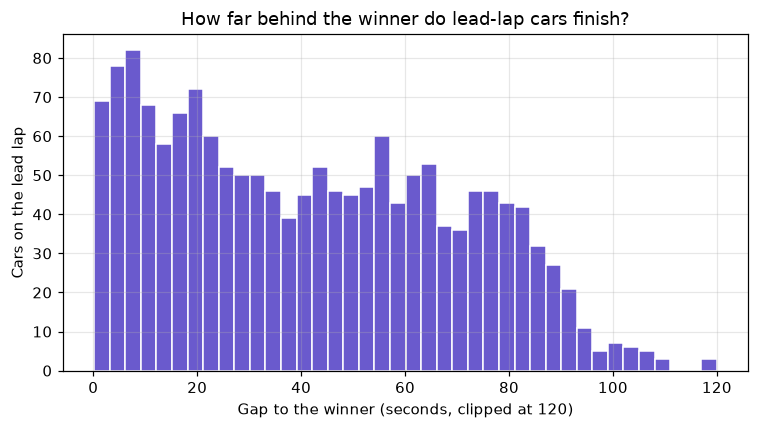

In [16]:
lead = races[(races["finish_position"] > 1) & races["gap_to_winner_s"].notna()]

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(lead["gap_to_winner_s"].clip(upper=120), bins=40, color="slateblue", edgecolor="white")
ax.set_xlabel("Gap to the winner (seconds, clipped at 120)")
ax.set_ylabel("Cars on the lead lap")
ax.set_title("How far behind the winner do lead-lap cars finish?")
save(fig, "gap_to_winner")

p2 = races[races["finish_position"] == 2].groupby("year")["gap_to_winner_s"].median().round(1)
print("Median gap from P2 to the winner (s):", p2.to_dict())

In [17]:
back = gridded[(~gridded["pit_lane_start"]) & (gridded["grid_position"] >= 18)]
pit = gridded[gridded["pit_lane_start"]]
cmp = pd.DataFrame({
    "cars": [len(pit), len(back)],
    "mean_finish": [pit["finish_position"].mean(), back["finish_position"].mean()],
    "mean_positions_gained": [pit["positions_gained"].mean(), back["positions_gained"].mean()],
    "retirement_rate": [pit["retired"].mean(), back["retired"].mean()],
}, index=["pit-lane start", "grid 18-20"]).round(2)
cmp

,cars,mean_finish,mean_positions_gained,retirement_rate
pit-lane start,22,13.27,6.86,0.18
grid 18-20,315,14.70,4.24,0.16


## 9. Key numbers for the report
First for all explored seasons (for the report), then for the training seasons only (for modelling decisions).

In [18]:
print(f"Seasons explored: {EDA_YEARS}  ({races.groupby(['year','round']).ngroups} races)")
print(f"Grid vs finish, Spearman: {rho_all:.2f}  (by year: {', '.join(f'{y}: {v:.2f}' for y, v in per_year.items())})")
print(f"Pole-sitters won {pole['win'].mean():.0%} of races and reached the podium {pole['podium'].mean():.0%}")
print(f"Drivers starting P1-P3 averaged a finish of {gridded[gridded.grid_position <= 3]['finish_position'].mean():.1f}; "
      f"grid P18-20 averaged {gridded[gridded.grid_position >= 18]['finish_position'].mean():.1f}")
print(f"Overall retirement rate: {started['retired'].mean():.1%} of starters")
print(f"Highest retirement team: {by_team.index[0]} ({by_team['retirement_rate'].iloc[0]:.1%}); "
      f"lowest: {by_team.index[-1]} ({by_team['retirement_rate'].iloc[-1]:.1%})")
print(f"Median gap of P2 to the winner: {p2.median():.1f} s")

tr = gridded[gridded["split"] == "train"]
tr_started = started[started["split"] == "train"]
tr_pole = tr[tr["grid_position"] == 1]
print("\nTRAINING SEASONS ONLY (2021-2023): use these numbers for modelling decisions")
print(f"  Grid vs finish, Spearman: {tr['grid_position'].corr(tr['finish_position'], method='spearman'):.2f}")
print(f"  Pole conversion to a win: {tr_pole['win'].mean():.0%}; podium: {tr_pole['podium'].mean():.0%}")
print(f"  Retirement rate: {tr_started['retired'].mean():.1%} of starters")

Seasons explored: [2021, 2022, 2023, 2024, 2025]  (114 races)
Grid vs finish, Spearman: 0.63  (by year: 2021: 0.64, 2022: 0.52, 2023: 0.60, 2024: 0.74, 2025: 0.65)
Pole-sitters won 54% of races and reached the podium 79%
Drivers starting P1-P3 averaged a finish of 4.2; grid P18-20 averaged 14.6
Overall retirement rate: 12.7% of starters
Highest retirement team: Williams (22.7%); lowest: McLaren (6.1%)
Median gap of P2 to the winner: 6.6 s

TRAINING SEASONS ONLY (2021-2023): use these numbers for modelling decisions
  Grid vs finish, Spearman: 0.58
  Pole conversion to a win: 53%; podium: 80%
  Retirement rate: 14.3% of starters
